
# The Great City Mobility Mystery 🚲
## PySpark Investigation

In this notebook, I investigate the city's bike-trip data to understand how the bike-sharing system is being used.

Instead of running random queries, I investigate real questions, check the output, and use the findings to identify areas that need attention.

### My investigation questions
1. When is bike demand highest?
2. Which stations have the most departures and arrivals?
3. Which stations show a possible imbalance in recorded trips?
4. Do membership types and bike types show different usage patterns?
5. What maintenance issues occur most often?
6. Are any trip records linked to missing users, bikes, or stations?
7. Which trips have unusually long durations?

I will use PySpark DataFrames, Spark window functions, and charts to investigate these questions.


In [1]:

from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.window import Window
import matplotlib.pyplot as plt

In [2]:

# I start Spark for my investigation.
spark = SparkSession.builder \
    .appName("CityMobilityInvestigation") \
    .getOrCreate()

In [3]:

# I load the clean datasets created by my validation pipeline.
stations = spark.read.parquet("outputs/clean/stations")
bikes = spark.read.parquet("outputs/clean/bikes")
users = spark.read.parquet("outputs/clean/users")
trips = spark.read.parquet("outputs/clean/trips")
maintenance = spark.read.parquet("outputs/clean/maintenance")


In [4]:

# I check how many records are available in each dataset.
print("Stations:", stations.count())
print("Bikes:", bikes.count())
print("Users:", users.count())
print("Trips:", trips.count())
print("Maintenance reports:", maintenance.count())


Stations: 8
Bikes: 213
Users: 1600
Trips: 4130
Maintenance reports: 289


## FIND THE BUSIEST HOURS

In [5]:
# I am considering completed trips to understand actual bike demand.
completed_trips = trips.filter(F.col("trip_status") == "completed")

# Demand by hour
hourly_demand = (
    completed_trips
    .withColumn("hour", F.hour("start_time_parsed"))
    .groupBy("hour")
    .agg(F.count("*").alias("total_trips"))
    .orderBy(F.desc("total_trips"))
)

hourly_demand.show(5)

+----+-----------+
|hour|total_trips|
+----+-----------+
|  22|        116|
|  14|        116|
|  12|        114|
|   3|        113|
|  11|        113|
+----+-----------+
only showing top 5 rows


## FIND THE BUSIEST WEEK DAY

In [6]:
# Demand by day of the week
daily_demand = (
    completed_trips
    .withColumn("day", F.date_format("start_time_parsed", "EEEE"))
    .groupBy("day")
    .agg(F.count("*").alias("total_trips"))
    .orderBy(F.desc("total_trips"))
)

daily_demand.show(1)

+------+-----------+
|   day|total_trips|
+------+-----------+
|Monday|        400|
+------+-----------+
only showing top 1 row


### STATION WITH DEPARTURE COUNT

In [7]:
# I am finding the stations where trips start most often.
departures = (
    completed_trips
    .groupBy("start_station_id")
    .agg(F.count("*").alias("departures"))
    .orderBy(F.desc("departures"))
)

departures.show(10)

+----------------+----------+
|start_station_id|departures|
+----------------+----------+
|            B006|       325|
|            B002|       318|
|            B008|       317|
|            B005|       312|
|            B001|       310|
|            B003|       309|
|            B004|       305|
|            B007|       289|
+----------------+----------+



### STATION WITH ARRIVAL COUNT

In [8]:
# I am finding the stations where trips end most often.
arrivals = (
    completed_trips
    .groupBy("end_station_id")
    .agg(F.count("*").alias("arrivals"))
    .orderBy(F.desc("arrivals"))
)

arrivals.show(10)

+--------------+--------+
|end_station_id|arrivals|
+--------------+--------+
|          B005|     335|
|          B007|     331|
|          B004|     327|
|          B003|     302|
|          B008|     301|
|          B002|     299|
|          B001|     296|
|          B006|     294|
+--------------+--------+



### DEPARTURES WITH STATION DETAILS

In [9]:
departure_details = departures.join(
    stations.select("station_id", "station_name", "district"),
    departures.start_station_id == stations.station_id,
    "left"
).select("station_id", "station_name", "district", "departures")

departure_details.show(10)

+----------+---------------+--------+----------+
|station_id|   station_name|district|departures|
+----------+---------------+--------+----------+
|      B002|     Riverfront|    east|       318|
|      B003|      Tech Park|    west|       309|
|      B008|      Lake View|    east|       317|
|      B001| Central Square| central|       310|
|      B004|University Gate|   north|       305|
|      B005|     Old Market|   south|       312|
|      B006|   Airport Link|   north|       325|
|      B007|    Museum Road| central|       289|
+----------+---------------+--------+----------+



### ARRIVALS WITH STATION DETAILS

In [10]:
arrival_details = arrivals.join(
    stations.select("station_id", "station_name", "district"),
    arrivals.end_station_id == stations.station_id,
    "left"
).select(
    F.col("end_station_id").alias("station_id"),
    "station_name",
    "district",
    "arrivals"
)

arrival_details.show(10, truncate=False)

+----------+---------------+--------+--------+
|station_id|station_name   |district|arrivals|
+----------+---------------+--------+--------+
|B002      |Riverfront     |east    |299     |
|B003      |Tech Park      |west    |302     |
|B008      |Lake View      |east    |301     |
|B001      |Central Square |central |296     |
|B004      |University Gate|north   |327     |
|B005      |Old Market     |south   |335     |
|B006      |Airport Link   |north   |294     |
|B007      |Museum Road    |central |331     |
+----------+---------------+--------+--------+



## STATION IMBALANCE

In [11]:
station_flow = (
    departures
    .select(
        F.col("start_station_id").alias("station_id"),
        "departures"
    )
    .join(
        arrivals.select(
            F.col("end_station_id").alias("station_id"),
            "arrivals"
        ),
        "station_id",
        "full"
    )
    .fillna(0, subset=["departures", "arrivals"])
    .withColumn("net_flow", F.col("departures") - F.col("arrivals"))
    .join(
        stations.select("station_id", "station_name", "district"),
        "station_id",
        "left"
    )
    .select(
        "station_id",
        "station_name",
        "district",
        "departures",
        "arrivals",
        "net_flow"
    )
    .orderBy(F.desc(F.abs(F.col("net_flow"))))
)

station_flow.show(10, truncate=False)

+----------+---------------+--------+----------+--------+--------+
|station_id|station_name   |district|departures|arrivals|net_flow|
+----------+---------------+--------+----------+--------+--------+
|B007      |Museum Road    |central |289       |331     |-42     |
|B006      |Airport Link   |north   |325       |294     |31      |
|B005      |Old Market     |south   |312       |335     |-23     |
|B004      |University Gate|north   |305       |327     |-22     |
|B002      |Riverfront     |east    |318       |299     |19      |
|B008      |Lake View      |east    |317       |301     |16      |
|B001      |Central Square |central |310       |296     |14      |
|B003      |Tech Park      |west    |309       |302     |7       |
+----------+---------------+--------+----------+--------+--------+



### STATION FLOW BY HOUR

The overall station balance can hide time-specific pressure. I compare departures and arrivals for each station and starting hour. This is a descriptive analysis, not a live inventory measurement.

In [12]:
# I count departures by station and hour.
departures_by_hour = (
    completed_trips
    .withColumn("hour", F.hour("start_time_parsed"))
    .groupBy(F.col("start_station_id").alias("station_id"), "hour")
    .agg(F.count("*").alias("departures"))
)

# I count arrivals by station and the trip's arrival hour.
arrivals_by_hour = (
    completed_trips
    .withColumn("hour", F.hour("end_time_parsed"))
    .groupBy(F.col("end_station_id").alias("station_id"), "hour")
    .agg(F.count("*").alias("arrivals"))
)

station_flow_by_hour = (
    departures_by_hour
    .join(arrivals_by_hour, ["station_id", "hour"], "full")
    .fillna(0, subset=["departures", "arrivals"])
    .withColumn("net_flow", F.col("departures") - F.col("arrivals"))
    .join(stations.select("station_id", "station_name", "district"), "station_id", "left")
    .select("station_id", "station_name", "district", "hour", "departures", "arrivals", "net_flow")
    .orderBy("station_id", "hour")
)

station_flow_by_hour.show(20, truncate=False)

+----------+--------------+--------+----+----------+--------+--------+
|station_id|station_name  |district|hour|departures|arrivals|net_flow|
+----------+--------------+--------+----+----------+--------+--------+
|B001      |Central Square|central |0   |11        |7       |4       |
|B001      |Central Square|central |1   |16        |9       |7       |
|B001      |Central Square|central |2   |13        |15      |-2      |
|B001      |Central Square|central |3   |12        |18      |-6      |
|B001      |Central Square|central |4   |14        |13      |1       |
|B001      |Central Square|central |5   |14        |21      |-7      |
|B001      |Central Square|central |6   |13        |13      |0       |
|B001      |Central Square|central |7   |12        |11      |1       |
|B001      |Central Square|central |8   |17        |11      |6       |
|B001      |Central Square|central |9   |9         |12      |-3      |
|B001      |Central Square|central |10  |20        |9       |11      |
|B001 

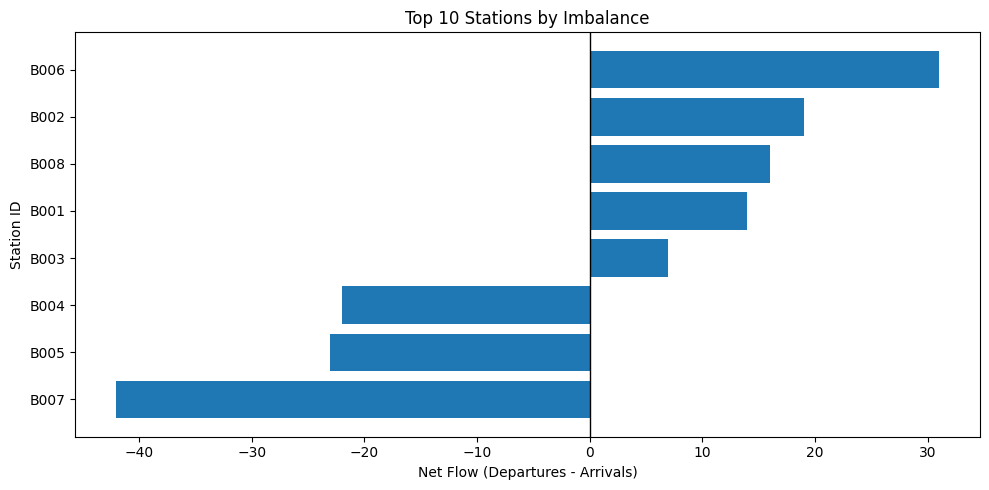

In [13]:
import matplotlib.pyplot as plt

# I select the 10 stations with the largest absolute imbalance
station_plot = (
    station_flow
    .withColumn("imbalance", F.abs(F.col("net_flow")))
    .orderBy(F.desc("imbalance"))
    .limit(10)
    .orderBy("net_flow")
    .toPandas()
)

plt.figure(figsize=(10, 5))
plt.barh(station_plot["station_id"], station_plot["net_flow"])

plt.axvline(0, color="black", linewidth=1)
plt.xlabel("Net Flow (Departures - Arrivals)")
plt.ylabel("Station ID")
plt.title("Top 10 Stations by Imbalance")
plt.tight_layout()
plt.show()

## USER MEMBERSHIP PATTERN

In [14]:
trip_user_details = completed_trips.join(
    users.select("user_id", "membership"),
    "user_id",
    "left"
)

membership_usage = (
    trip_user_details
    .groupBy("membership")
    .agg(
        F.count("*").alias("total_trips"),
        F.round(F.avg("duration_minutes_parsed"), 2).alias("average_duration")
    )
    .orderBy(F.desc("total_trips"))
)

membership_usage.show()

+----------+-----------+----------------+
|membership|total_trips|average_duration|
+----------+-----------+----------------+
|    annual|        922|          208.93|
|   student|        556|          206.57|
|    casual|        524|          193.75|
|   monthly|        483|           208.5|
+----------+-----------+----------------+



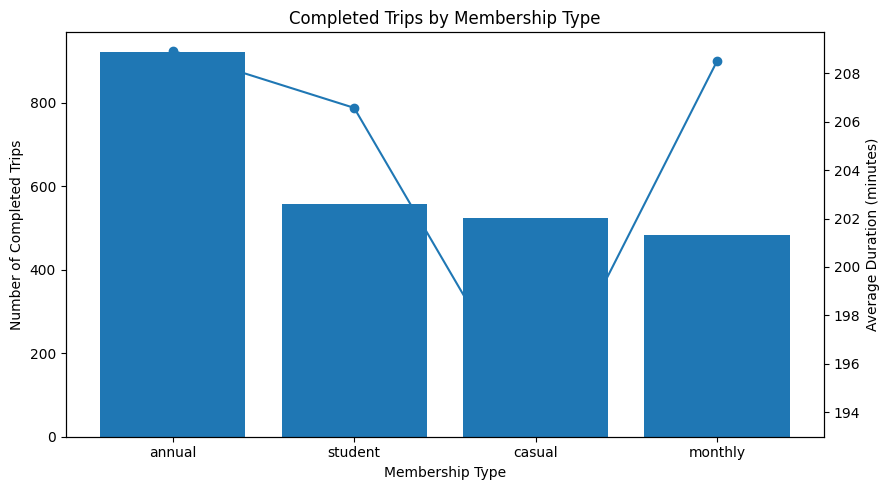

In [15]:
membership_plot = membership_usage.toPandas()

fig, ax1 = plt.subplots(figsize=(9, 5))

ax1.bar(
    membership_plot["membership"].fillna("Unknown"),
    membership_plot["total_trips"]
)
ax1.set_xlabel("Membership Type")
ax1.set_ylabel("Number of Completed Trips")
ax1.set_title("Completed Trips by Membership Type")

ax2 = ax1.twinx()
ax2.plot(
    membership_plot["membership"].fillna("Unknown"),
    membership_plot["average_duration"],
    marker="o"
)
ax2.set_ylabel("Average Duration (minutes)")

plt.tight_layout()
plt.show()

## BIKE TYPE PATTERN

In [16]:
trip_bike_details = completed_trips.join(
    bikes.select("bike_id", "bike_type"),
    "bike_id",
    "left"
)

bike_type_usage = (
    trip_bike_details
    .groupBy("bike_type")
    .agg(
        F.count("*").alias("total_trips"),
        F.round(F.avg("duration_minutes_parsed"), 2).alias("average_duration")
    )
    .orderBy(F.desc("total_trips"))
)

bike_type_usage.show()

+---------+-----------+----------------+
|bike_type|total_trips|average_duration|
+---------+-----------+----------------+
| standard|        873|          202.32|
| electric|        462|          208.22|
|   e-bike|        422|          205.53|
|    cargo|        369|          207.43|
|     NULL|        359|          205.08|
+---------+-----------+----------------+



### CHECK BIKE-DIMENSION JOIN QUALITY

The `bike_type` NULL group here is created by joining completed trips to the **clean bikes** dataset. In this project, bikes with an `unknown` purchase year are quarantined as whole rows, while trip reference validation checks the original transformed parent data. Therefore, a trip can pass validation but fail to find its bike in the clean-bike table. This is a downstream join-quality issue, not proof that raw bike_type was blank.

In [17]:
# I compare completed trips that do and do not find a matching clean bike row.
bike_join_quality = (
    completed_trips
    .join(bikes.select("bike_id").withColumn("bike_dimension_match", F.lit(True)), "bike_id", "left")
    .withColumn(
        "bike_dimension_match",
        F.coalesce(F.col("bike_dimension_match"), F.lit(False))
    )
    .groupBy("bike_dimension_match")
    .agg(F.count("*").alias("trip_count"))
    .withColumn(
        "trip_percentage",
        F.round(F.col("trip_count") * 100.0 / F.sum("trip_count").over(Window.partitionBy()), 2)
    )
    .orderBy(F.desc("bike_dimension_match"))
)

bike_join_quality.show(truncate=False)

+--------------------+----------+---------------+
|bike_dimension_match|trip_count|trip_percentage|
+--------------------+----------+---------------+
|true                |2126      |85.55          |
|false               |359       |14.45          |
+--------------------+----------+---------------+



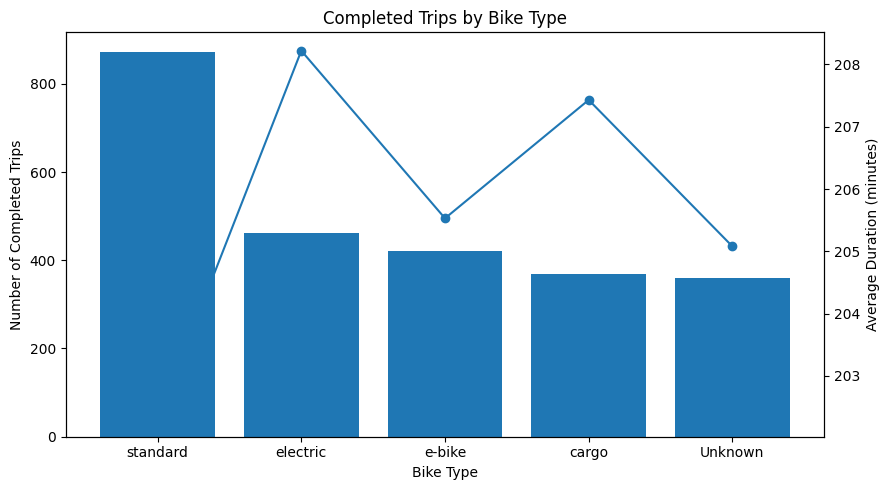

In [18]:
bike_plot = bike_type_usage.toPandas()

fig, ax1 = plt.subplots(figsize=(9, 5))

bike_labels = bike_plot["bike_type"].fillna("Unknown")

ax1.bar(bike_labels, bike_plot["total_trips"])
ax1.set_xlabel("Bike Type")
ax1.set_ylabel("Number of Completed Trips")
ax1.set_title("Completed Trips by Bike Type")

ax2 = ax1.twinx()
ax2.plot(
    bike_labels,
    bike_plot["average_duration"],
    marker="o"
)
ax2.set_ylabel("Average Duration (minutes)")

plt.tight_layout()
plt.show()

## MOST COMMON MAINTENANCE ISSUE

In [19]:
maintenance_issues = (
    maintenance
    .groupBy("issue_type")
    .agg(
        F.count("*").alias("total_reports"),
        F.round(F.avg("repair_minutes_parsed"), 2).alias("avg_repair_minutes")
    )
    .orderBy(F.desc("total_reports"))
)

maintenance_issues.show(truncate=False)

+----------+-------------+------------------+
|issue_type|total_reports|avg_repair_minutes|
+----------+-------------+------------------+
|vandalism |60           |143.88            |
|flat_tire |53           |105.38            |
|chain     |50           |106.44            |
|brake     |44           |133.48            |
|other     |43           |134.81            |
|battery   |39           |116.41            |
+----------+-------------+------------------+



### MAINTENANCE RESOLUTION STATUS

The source contains a `resolution` field. I normalize it for reporting: `fixed` and `replaced` are treated as resolved, `pending` remains pending, and blank or null values are reported as unknown rather than assumed to be unresolved.

In [20]:
maintenance_resolution = (
    maintenance
    .withColumn("resolution_normalized", F.lower(F.trim(F.col("resolution"))))
    .withColumn(
        "resolution_status",
        F.when(F.col("resolution_normalized").isin("fixed", "replaced"), "resolved")
         .when(F.col("resolution_normalized") == "pending", "pending")
         .otherwise("unknown")
    )
    .groupBy("resolution_status")
    .agg(F.count("*").alias("total_reports"))
    .orderBy(F.desc("total_reports"))
)

maintenance_resolution.show(truncate=False)

+-----------------+-------------+
|resolution_status|total_reports|
+-----------------+-------------+
|resolved         |167          |
|unknown          |62           |
|pending          |60           |
+-----------------+-------------+



#### TRIPS WITH MISSING STATION AND USER

In [21]:
# I am checking trips that were quarantined because of data quality issues.
quarantined_trips = spark.read.parquet("outputs/quarantine/trips")

# I am finding trips with missing or unmatched references.
reference_issues = quarantined_trips.filter(
    F.col("_quarantine_reason").rlike(
        "Unmatched user_id|Unmatched bike_id|Unmatched start_station_id|Unmatched end_station_id|Missing user_id|Missing bike_id|Missing start_station_id|Missing end_station_id"
    )
)

reference_issues.select(
    "trip_id",
    "user_id",
    "bike_id",
    "start_station_id",
    "end_station_id",
    "_quarantine_reason"
).show(truncate=False)

+-------+-------+-------+----------------+--------------+--------------------------+
|trip_id|user_id|bike_id|start_station_id|end_station_id|_quarantine_reason        |
+-------+-------+-------+----------------+--------------+--------------------------+
|T000022|U01286 |BK0066 |B999            |B003          |Unmatched start_station_id|
|T000053|NULL   |BK0138 |B001            |B005          |Missing user_id           |
+-------+-------+-------+----------------+--------------+--------------------------+



## TRIPS WITH LONG DURATIONS

In [22]:
longest_trips = (
    completed_trips
    .select(
        "trip_id",
        "user_id",
        "bike_id",
        "start_station_id",
        "end_station_id",
        "duration_minutes_parsed"
    )
    .orderBy(F.desc("duration_minutes_parsed"))
)

longest_trips.show(10, truncate=False)

+-------+-------+-------+----------------+--------------+-----------------------+
|trip_id|user_id|bike_id|start_station_id|end_station_id|duration_minutes_parsed|
+-------+-------+-------+----------------+--------------+-----------------------+
|T003767|U00045 |BK0165 |B005            |B005          |700.0                  |
|T002906|U01374 |BK0013 |B001            |B003          |699.0                  |
|T002874|U01020 |BK0077 |B008            |B004          |698.0                  |
|T003285|U00466 |BK0146 |B005            |B003          |698.0                  |
|T000384|U00172 |BK0199 |B007            |B004          |696.0                  |
|T000868|U00323 |BK0168 |B001            |B004          |696.0                  |
|T001454|U00020 |BK0132 |B007            |B006          |696.0                  |
|T001483|U00962 |BK0092 |B001            |B002          |696.0                  |
|T002050|U00546 |BK0011 |B002            |B002          |696.0                  |
|T001448|U00742 

### FLAG LONG TRIPS FOR REVIEW

The source data does not provide an official long-trip cutoff. I use 180 minutes (3 hours) as an **exploratory review threshold only**. These trips remain in the data; the flag is not a validation failure or automatic quarantine rule.

In [23]:
# This threshold is only for investigation and can be changed here.
LONG_TRIP_THRESHOLD_MINUTES = 180

long_trip_review = (
    completed_trips
    .select(
        "trip_id", "user_id", "bike_id", "start_station_id",
        "end_station_id", "duration_minutes_parsed"
    )
    .withColumn(
        "long_trip_flag",
        F.col("duration_minutes_parsed") > LONG_TRIP_THRESHOLD_MINUTES
    )
    .filter(F.col("long_trip_flag"))
    .orderBy(F.desc("duration_minutes_parsed"))
)

print("Exploratory threshold (minutes):", LONG_TRIP_THRESHOLD_MINUTES)
print("Trips flagged for review:", long_trip_review.count())
long_trip_review.show(10, truncate=False)

Exploratory threshold (minutes): 180
Trips flagged for review: 844
+-------+-------+-------+----------------+--------------+-----------------------+--------------+
|trip_id|user_id|bike_id|start_station_id|end_station_id|duration_minutes_parsed|long_trip_flag|
+-------+-------+-------+----------------+--------------+-----------------------+--------------+
|T003767|U00045 |BK0165 |B005            |B005          |700.0                  |true          |
|T002906|U01374 |BK0013 |B001            |B003          |699.0                  |true          |
|T002874|U01020 |BK0077 |B008            |B004          |698.0                  |true          |
|T003285|U00466 |BK0146 |B005            |B003          |698.0                  |true          |
|T000384|U00172 |BK0199 |B007            |B004          |696.0                  |true          |
|T000868|U00323 |BK0168 |B001            |B004          |696.0                  |true          |
|T001454|U00020 |BK0132 |B007            |B006          |696

# WINDOW FUNCTIONS

### RANK THE BUSIEST STATIONS WITHIN EACH DISTRICT

In [24]:
# I am counting departures from each station.
station_departures = (
    completed_trips
    .groupBy("start_station_id")
    .agg(F.count("*").alias("departures"))
    .join(
        stations.select("station_id", "station_name", "district"),
        F.col("start_station_id") == F.col("station_id"),
        "left"
    )
    .select("station_id", "station_name", "district", "departures")
)

# I am ranking stations within each district by their departures.
district_window = Window.partitionBy("district").orderBy(
    F.desc("departures")
)

ranked_stations = station_departures.withColumn(
    "station_rank",
    F.dense_rank().over(district_window)
)

ranked_stations.orderBy("district", "station_rank").show(
    20, truncate=False
)

+----------+---------------+--------+----------+------------+
|station_id|station_name   |district|departures|station_rank|
+----------+---------------+--------+----------+------------+
|B001      |Central Square |central |310       |1           |
|B007      |Museum Road    |central |289       |2           |
|B002      |Riverfront     |east    |318       |1           |
|B008      |Lake View      |east    |317       |2           |
|B006      |Airport Link   |north   |325       |1           |
|B004      |University Gate|north   |305       |2           |
|B005      |Old Market     |south   |312       |1           |
|B003      |Tech Park      |west    |309       |1           |
+----------+---------------+--------+----------+------------+



### 

### CUMULATIVE DAILY TRIP DEMAND

In [25]:
# I am counting completed trips for each day.
daily_trips = (
    completed_trips
    .withColumn(
        "trip_date",
        F.to_date("start_time_parsed")
    )
    .groupBy("trip_date")
    .agg(F.count("*").alias("daily_trips"))
)

# I am calculating the cumulative number of trips over time.
running_window = (
    Window.orderBy("trip_date")
    .rowsBetween(Window.unboundedPreceding, Window.currentRow)
)

daily_running_total = daily_trips.withColumn(
    "cumulative_trips",
    F.sum("daily_trips").over(running_window)
)

daily_running_total.orderBy("trip_date").show(30)

+----------+-----------+----------------+
| trip_date|daily_trips|cumulative_trips|
+----------+-----------+----------------+
|2026-08-01|         84|              84|
|2026-08-02|         74|             158|
|2026-08-03|         72|             230|
|2026-08-04|         79|             309|
|2026-08-05|         92|             401|
|2026-08-06|         86|             487|
|2026-08-07|         77|             564|
|2026-08-08|         65|             629|
|2026-08-09|         81|             710|
|2026-08-10|         77|             787|
|2026-08-11|         71|             858|
|2026-08-12|         63|             921|
|2026-08-13|         82|            1003|
|2026-08-14|         84|            1087|
|2026-08-15|         78|            1165|
|2026-08-16|         93|            1258|
|2026-08-17|         89|            1347|
|2026-08-18|         77|            1424|
|2026-08-19|         88|            1512|
|2026-08-20|         82|            1594|
|2026-08-21|         93|          

### Top five longest trips per bike type

In [26]:
# I am adding bike types to completed trip records.
trips_with_bikes = completed_trips.join(
    bikes.select("bike_id", "bike_type"),
    "bike_id",
    "left"
)

# I am ranking trips from longest to shortest within each bike type.
bike_window = Window.partitionBy("bike_type").orderBy(
    F.desc("duration_minutes_parsed"),
    F.asc("trip_id")
)

ranked_trips = trips_with_bikes.withColumn(
    "trip_rank",
    F.row_number().over(bike_window)
)

longest_by_bike_type = ranked_trips.filter(
    F.col("trip_rank") <= 5
).select(
    "bike_type",
    "trip_id",
    "duration_minutes_parsed",
    "trip_rank"
)

longest_by_bike_type.orderBy(
    "bike_type", "trip_rank"
).show(30, truncate=False)

+---------+-------+-----------------------+---------+
|bike_type|trip_id|duration_minutes_parsed|trip_rank|
+---------+-------+-----------------------+---------+
|NULL     |T000384|696.0                  |1        |
|NULL     |T001448|695.0                  |2        |
|NULL     |T003423|695.0                  |3        |
|NULL     |T001816|687.0                  |4        |
|NULL     |T003135|686.0                  |5        |
|cargo    |T001454|696.0                  |1        |
|cargo    |T001787|692.0                  |2        |
|cargo    |T002694|691.0                  |3        |
|cargo    |T000116|688.0                  |4        |
|cargo    |T004020|677.0                  |5        |
|e-bike   |T004141|691.0                  |1        |
|e-bike   |T001824|690.0                  |2        |
|e-bike   |T004053|690.0                  |3        |
|e-bike   |T002521|686.0                  |4        |
|e-bike   |T000373|685.0                  |5        |
|electric |T003767|700.0    

# SPARK SQL & DATAFRAME COMPARSION

In [27]:
# I am making the validated DataFrames available to Spark SQL.
completed_trips.createOrReplaceTempView("completed_trips")
stations.createOrReplaceTempView("stations")
users.createOrReplaceTempView("users")
bikes.createOrReplaceTempView("bikes")
maintenance.createOrReplaceTempView("maintenance")

In [28]:
# I am checking whether the SQL and DataFrame results match.
def compare_results(sql_df, dataframe_df, analysis_name):
    sql_only = sql_df.exceptAll(dataframe_df).count()
    dataframe_only = dataframe_df.exceptAll(sql_df).count()

    print(f"{analysis_name}:")
    print("Rows found only in SQL:", sql_only)
    print("Rows found only in DataFrame:", dataframe_only)
    print("Results match:", sql_only == 0 and dataframe_only == 0)

In [29]:
hourly_sql = spark.sql("""
    SELECT
        HOUR(start_time_parsed) AS hour,
        COUNT(*) AS total_trips
    FROM completed_trips
    GROUP BY HOUR(start_time_parsed)
    ORDER BY total_trips DESC
""")

hourly_sql.show()

+----+-----------+
|hour|total_trips|
+----+-----------+
|  22|        116|
|  14|        116|
|  12|        114|
|   3|        113|
|  11|        113|
|  18|        112|
|   4|        111|
|  23|        111|
|   1|        110|
|   6|        109|
|  16|        106|
|  15|        106|
|  17|        105|
|  10|        102|
|  21|        102|
|   5|        101|
|   2|        101|
|  13|        100|
|  19|         98|
|  20|         94|
+----+-----------+
only showing top 20 rows


In [30]:
hourly_df = (
    completed_trips
    .groupBy(F.hour("start_time_parsed").alias("hour"))
    .agg(F.count("*").alias("total_trips"))
)

compare_results(
    hourly_sql,
    hourly_df,
    "Hourly demand"
)

Hourly demand:
Rows found only in SQL: 0
Rows found only in DataFrame: 0
Results match: True


In [31]:
station_flow_sql = spark.sql("""
    WITH station_events AS (
        SELECT start_station_id AS station_id,
               1 AS departure,
               0 AS arrival
        FROM completed_trips

        UNION ALL

        SELECT end_station_id AS station_id,
               0 AS departure,
               1 AS arrival
        FROM completed_trips
    )
    SELECT
        station_id,
        SUM(departure) AS departures,
        SUM(arrival) AS arrivals,
        SUM(departure) - SUM(arrival) AS net_flow
    FROM station_events
    GROUP BY station_id
    ORDER BY ABS(net_flow) DESC
""")

station_flow_sql.show(10, truncate=False)

+----------+----------+--------+--------+
|station_id|departures|arrivals|net_flow|
+----------+----------+--------+--------+
|B007      |289       |331     |-42     |
|B006      |325       |294     |31      |
|B005      |312       |335     |-23     |
|B004      |305       |327     |-22     |
|B002      |318       |299     |19      |
|B008      |317       |301     |16      |
|B001      |310       |296     |14      |
|B003      |309       |302     |7       |
+----------+----------+--------+--------+



In [32]:
departure_counts = completed_trips.groupBy(
    F.col("start_station_id").alias("station_id")
).agg(F.count("*").alias("departures"))

arrival_counts = completed_trips.groupBy(
    F.col("end_station_id").alias("station_id")
).agg(F.count("*").alias("arrivals"))

station_flow_df = (
    departure_counts
    .join(arrival_counts, "station_id", "full")
    .fillna(0, subset=["departures", "arrivals"])
    .withColumn(
        "net_flow",
        F.col("departures") - F.col("arrivals")
    )
    .select("station_id", "departures", "arrivals", "net_flow")
)

compare_results(
    station_flow_sql,
    station_flow_df,
    "Station net flow"
)

Station net flow:
Rows found only in SQL: 0
Rows found only in DataFrame: 0
Results match: True


In [33]:
maintenance_sql = spark.sql("""
    SELECT
        issue_type,
        COUNT(*) AS total_reports,
        ROUND(AVG(repair_minutes_parsed), 2) AS avg_repair_minutes
    FROM maintenance
    GROUP BY issue_type
    ORDER BY total_reports DESC
""")

maintenance_sql.show(truncate=False)

+----------+-------------+------------------+
|issue_type|total_reports|avg_repair_minutes|
+----------+-------------+------------------+
|vandalism |60           |143.88            |
|flat_tire |53           |105.38            |
|chain     |50           |106.44            |
|brake     |44           |133.48            |
|other     |43           |134.81            |
|battery   |39           |116.41            |
+----------+-------------+------------------+



In [34]:
maintenance_df = (
    maintenance
    .groupBy("issue_type")
    .agg(
        F.count("*").alias("total_reports"),
        F.round(F.avg("repair_minutes_parsed"), 2)
         .alias("avg_repair_minutes")
    )
)

compare_results(
    maintenance_sql,
    maintenance_df,
    "Maintenance issue analysis"
)

Maintenance issue analysis:
Rows found only in SQL: 0
Rows found only in DataFrame: 0
Results match: True


# EXPLAIN 

In [35]:
# I am inspecting how Spark plans the station-flow calculation.
station_flow_df.explain("formatted")

== Physical Plan ==
AdaptiveSparkPlan (18)
+- Project (17)
   +- Project (16)
      +- SortMergeJoin FullOuter (15)
         :- Sort (7)
         :  +- HashAggregate (6)
         :     +- Exchange (5)
         :        +- HashAggregate (4)
         :           +- Project (3)
         :              +- Filter (2)
         :                 +- Scan parquet  (1)
         +- Sort (14)
            +- HashAggregate (13)
               +- Exchange (12)
                  +- HashAggregate (11)
                     +- Project (10)
                        +- Filter (9)
                           +- Scan parquet  (8)


(1) Scan parquet 
Output [2]: [start_station_id#21, trip_status#26]
Batched: true
Location: InMemoryFileIndex [file:/c:/Users/Likhita/Downloads/city_mobility_pipeline_updated/city_mobility_pipeline/outputs/clean/trips]
PushedFilters: [IsNotNull(trip_status), EqualTo(trip_status,completed)]
ReadSchema: struct<start_station_id:string,trip_status:string>

(2) Filter
Input [2]: [start_s

In [36]:
# I am inspecting the plan for bike-type usage analysis.
bike_type_usage.explain("formatted")

== Physical Plan ==
AdaptiveSparkPlan (33)
+- == Final Plan ==
   ResultQueryStage (21)
   +- * Sort (20)
      +- AQEShuffleRead (19), coalesced
         +- ShuffleQueryStage (18), Statistics(sizeInBytes=192.0 B, rowCount=5)
            +- Exchange (17)
               +- * HashAggregate (16)
                  +- AQEShuffleRead (15), coalesced
                     +- ShuffleQueryStage (14), Statistics(sizeInBytes=232.0 B, rowCount=5)
                        +- Exchange (13)
                           +- * HashAggregate (12)
                              +- * Project (11)
                                 +- * BroadcastHashJoin LeftOuter BuildRight (10)
                                    :- * Project (4)
                                    :  +- * Filter (3)
                                    :     +- * ColumnarToRow (2)
                                    :        +- Scan parquet  (1)
                                    +- BroadcastQueryStage (9), Statistics(sizeInBytes=2.0 MiB, rowCo

## SAVE ANALYTICAL OUTPUT DATASETS

The ETL pipeline saves clean and quarantined data. This final notebook section separately saves the investigation results as Parquet under `outputs/analytics/`, so they can be reused without rerunning every analysis. Run the notebook from the project root after running `python main.py`.

In [37]:
from pathlib import Path

# I keep investigation outputs separate from clean and quarantined source datasets.
ANALYTICS_OUTPUT_DIR = Path("outputs/analytics")
ANALYTICS_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

analytics_outputs = {
    "hourly_demand": hourly_demand,
    "daily_demand": daily_demand,
    "station_flow": station_flow,
    "station_flow_by_hour": station_flow_by_hour,
    "membership_usage": membership_usage,
    "bike_type_usage": bike_type_usage,
    "bike_join_quality": bike_join_quality,
    "maintenance_issues": maintenance_issues,
    "maintenance_resolution": maintenance_resolution,
    "long_trip_review": long_trip_review,
}

for output_name, output_df in analytics_outputs.items():
    output_path = ANALYTICS_OUTPUT_DIR / output_name
    output_df.write.mode("overwrite").parquet(str(output_path))
    print(f"Saved {output_name} to {output_path}")

Saved hourly_demand to outputs\analytics\hourly_demand
Saved daily_demand to outputs\analytics\daily_demand
Saved station_flow to outputs\analytics\station_flow
Saved station_flow_by_hour to outputs\analytics\station_flow_by_hour
Saved membership_usage to outputs\analytics\membership_usage
Saved bike_type_usage to outputs\analytics\bike_type_usage
Saved bike_join_quality to outputs\analytics\bike_join_quality
Saved maintenance_issues to outputs\analytics\maintenance_issues
Saved maintenance_resolution to outputs\analytics\maintenance_resolution
Saved long_trip_review to outputs\analytics\long_trip_review
